# Research Experiment 1 — ITSM Incident Priority Classification

## 1. Load and inspect the dataset

1. Import libraries

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


2. Load dataset

In [63]:
df = pd.read_csv("ITSM_data.csv")

print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

Dataset shape: (46606, 25)

First five records:


/tmp/ipykernel_1487/985635864.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("ITSM_data.csv")


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4.0,0.601292,...,NaN,4/11/2013 13:50,4/11/2013 13:51,"3,87,16,91,111",Other,1.0,SD0000007,2.0,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3.0,0.415050,...,2/12/2013 12:31,2/12/2013 12:36,2/12/2013 12:36,"4,35,47,86,389",Software,1.0,SD0000011,1.0,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551,...,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1.0,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4.0,0.642927,...,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1.0,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4.0,0.345258,...,NaN,8/11/2013 13:55,8/11/2013 13:55,"3,38,39,03,333",Other,1.0,SD0000029,NaN,NaN,NaN


3. Check dataset quality

In [64]:
print("Total records:", len(df))

print("\nMissing target values:")
print(df["Priority"].isnull().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate Incident IDs:")
print(df["Incident_ID"].duplicated().sum())

print("\nPriority distribution:")
print(df["Priority"].value_counts(dropna=False))

Total records: 46606

Missing target values:
1380

Exact duplicate rows:
0

Duplicate Incident IDs:
0

Priority distribution:
Priority
4.0    22717
5.0    16486
3.0     5323
NaN     1380
2.0      697
1.0        3
Name: count, dtype: int64


4. Clean the dataset

In [65]:
# Remove records without known priority
df_clean = df.dropna(subset=["Priority"]).copy()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Convert priority to integer
df_clean["Priority"] = df_clean["Priority"].astype(int)

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

print("\nCleaned priority distribution:")
print(
    df_clean["Priority"]
    .value_counts()
    .sort_index()
)

Original records: 46606
Cleaned records: 45226

Cleaned priority distribution:
Priority
1        3
2      697
3     5323
4    22717
5    16486
Name: count, dtype: int64


5. Visualize priority distribution

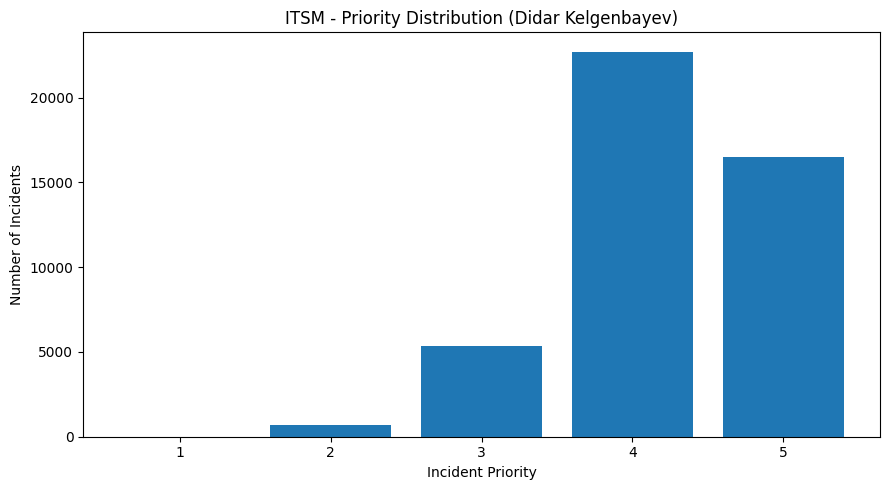

Priority distribution:


,count
Priority,
1,3
2,697
3,5323
4,22717
5,16486


In [66]:
priority_counts = (
    df_clean["Priority"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    priority_counts.index.astype(str),
    priority_counts.values
)

plt.xlabel("Incident Priority")
plt.ylabel("Number of Incidents")
plt.title(
    "ITSM - Priority Distribution "
    "(Didar Kelgenbayev)"
)

plt.tight_layout()

plt.savefig(
    "research_priority_distribution.png",
    dpi=300
)

plt.show()

print("Priority distribution:")
display(priority_counts)

## 2. Prepare the train/test split

6. Define features and target

In [67]:
from sklearn.model_selection import train_test_split

features_A = [
    "CI_Cat",
    "CI_Subcat",
    "Impact",
    "Urgency",
    "Category"
]

features_B = [
    "CI_Cat",
    "CI_Subcat",
    "Category"
]

# Keep all five columns for now
X = df_clean[features_A]
y = df_clean["Priority"]

print("Features A:", features_A)
print("Features B:", features_B)
print("Target: Priority")

Features A: ['CI_Cat', 'CI_Subcat', 'Impact', 'Urgency', 'Category']
Features B: ['CI_Cat', 'CI_Subcat', 'Category']
Target: Priority


7. Split the dataset

In [68]:
# Separate extremely rare Priority 1 records
rare = df_clean[df_clean["Priority"] == 1]
common = df_clean[df_clean["Priority"] != 1]

# Stratified split for remaining classes
train_common, test_common = train_test_split(
    common,
    test_size=0.2,
    random_state=42,
    stratify=common["Priority"]
)

# Put 2 rare records in training, 1 in testing
rare = rare.sample(frac=1, random_state=42)

train_df = pd.concat([
    train_common,
    rare.iloc[:2]
])

test_df = pd.concat([
    test_common,
    rare.iloc[2:]
])

# Shuffle records
train_df = train_df.sample(frac=1, random_state=42)
test_df = test_df.sample(frac=1, random_state=42)

X_train = train_df[features_A]
X_test = test_df[features_A]

y_train = train_df["Priority"]
y_test = test_df["Priority"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training records: 36180
Testing records: 9046

Training class distribution:
Priority
1        2
2      558
3     4258
4    18173
5    13189
Name: count, dtype: int64

Testing class distribution:
Priority
1       1
2     139
3    1065
4    4544
5    3297
Name: count, dtype: int64


## 3. Establish the baseline

8. Train the Dummy Classifier

In [69]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

y_baseline = baseline.predict(X_test)

baseline_results = {
    "Accuracy": accuracy_score(
        y_test, y_baseline
    ),
    "Macro Precision": precision_score(
        y_test, y_baseline,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_baseline,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_baseline,
        average="macro",
        zero_division=0
    )
}

print("Baseline prediction class:", baseline.classes_[
    baseline.class_prior_.argmax()
])

print("\nBaseline results:")
display(pd.DataFrame(
    [baseline_results]
).round(4))

Baseline prediction class: 4

Baseline results:


,Accuracy,Macro Precision,Macro Recall,Macro F1
0,0.5023,0.1005,0.2,0.1337


## 4. Train and compare the ML models

9. Import ML libraries

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("ML libraries imported!")

ML libraries imported!


10. Create preprocessing

In [71]:
def make_preprocessor(selected_features):
    categorical_pipeline = Pipeline([
        ("to_string", FunctionTransformer(
            lambda x: x.fillna("Missing").astype(str)
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    return ColumnTransformer([
        ("cat", categorical_pipeline, selected_features)
    ])

print("Preprocessing function created!")

Preprocessing function created!


11. Train both models with both configurations

In [72]:
# Define the two feature configurations and the two models.
# These definitions were missing from the original notebook.
experiments = {
    "A - With Impact and Urgency": features_A,
    "B - Without Impact and Urgency": features_B,
}

model_types = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

from sklearn.base import clone

research_models = {}
research_results = []

for experiment_name, selected_features in experiments.items():
    for model_name, model in model_types.items():
        # Fresh preprocessor for each fitted model prevents feature-count mismatch.
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(selected_features)),
            ("classifier", clone(model)),
        ])
        pipeline.fit(train_df[selected_features], y_train)
        predictions = pipeline.predict(test_df[selected_features])
        research_results.append({
            "Experiment": experiment_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Macro F1": f1_score(y_test, predictions, average="macro", zero_division=0),
        })
        research_models[(experiment_name, model_name)] = pipeline
        print(experiment_name, "-", model_name, "completed")

research_results_df = pd.DataFrame(research_results)
display(research_results_df.round(4))

A - With Impact and Urgency - Decision Tree completed
A - With Impact and Urgency - Random Forest completed
B - Without Impact and Urgency - Decision Tree completed
B - Without Impact and Urgency - Random Forest completed


,Experiment,Model,Accuracy,Macro F1
0,A - With Impact and Urgency,Decision Tree,0.9998,0.9331
1,A - With Impact and Urgency,Random Forest,0.9997,0.9989
2,B - Without Impact and Urgency,Decision Tree,0.7138,0.4332
3,B - Without Impact and Urgency,Random Forest,0.7189,0.4517


12. Add the baseline to the comparison

In [73]:
baseline_row = pd.DataFrame([{
    "Experiment": "Baseline",
    "Model": "Most Frequent Class",
    "Accuracy": baseline_results["Accuracy"],
    "Macro F1": baseline_results["Macro F1"]
}])

final_results = pd.concat(
    [baseline_row, research_results_df],
    ignore_index=True
)

display(final_results.round(4))

final_results.to_csv(
    "research_experiment_1_results.csv",
    index=False
)

,Experiment,Model,Accuracy,Macro F1
0,Baseline,Most Frequent Class,0.5023,0.1337
1,A - With Impact and Urgency,Decision Tree,0.9998,0.9331
2,A - With Impact and Urgency,Random Forest,0.9997,0.9989
3,B - Without Impact and Urgency,Decision Tree,0.7138,0.4332
4,B - Without Impact and Urgency,Random Forest,0.7189,0.4517


13. Visualize the comparison

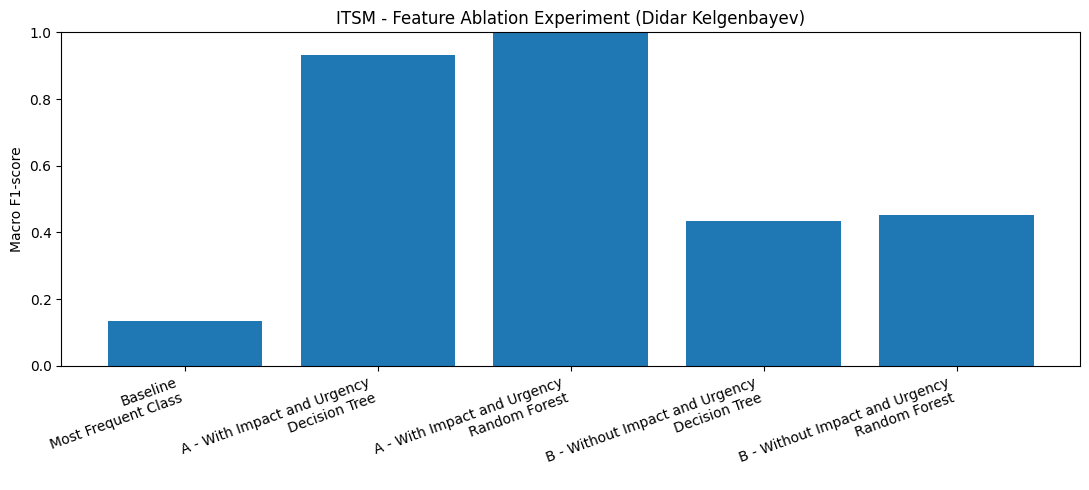

In [74]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

labels = (
    final_results["Experiment"] + "\n" +
    final_results["Model"]
)

plt.bar(
    labels,
    final_results["Macro F1"]
)

plt.ylabel("Macro F1-score")
plt.title(
    "ITSM - Feature Ablation Experiment "
    "(Didar Kelgenbayev)"
)

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    "research_feature_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Analyze confusion matrices and individual priorities

14. Classification reports

In [75]:
from sklearn.metrics import classification_report

for (experiment_name, model_name), model in research_models.items():

    selected_features = experiments[experiment_name]

    predictions = model.predict(
        test_df[selected_features]
    )

    print("\n" + "=" * 60)
    print(experiment_name, "-", model_name)
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions,
        labels=[1, 2, 3, 4, 5],
        zero_division=0
    ))


A - With Impact and Urgency - Decision Tree
              precision    recall  f1-score   support

           1       0.50      1.00      0.67         1
           2       1.00      1.00      1.00       139
           3       1.00      1.00      1.00      1065
           4       1.00      1.00      1.00      4544
           5       1.00      1.00      1.00      3297

    accuracy                           1.00      9046
   macro avg       0.90      1.00      0.93      9046
weighted avg       1.00      1.00      1.00      9046


A - With Impact and Urgency - Random Forest
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         1
           2       1.00      0.99      1.00       139
           3       1.00      1.00      1.00      1065
           4       1.00      1.00      1.00      4544
           5       1.00      1.00      1.00      3297

    accuracy                           1.00      9046
   macro avg       1.00      1.00      1.

15. Generate confusion matrices

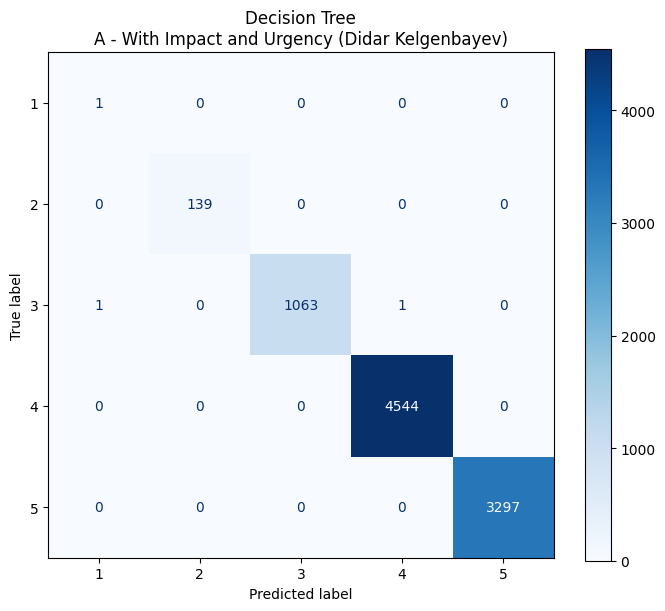

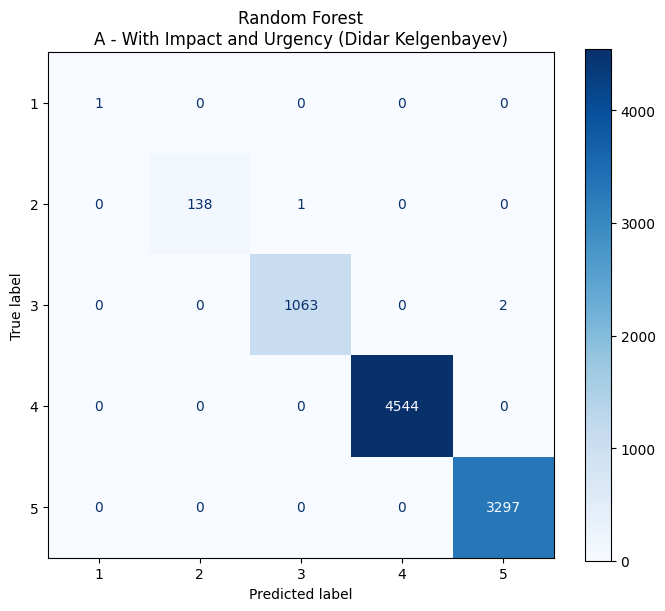

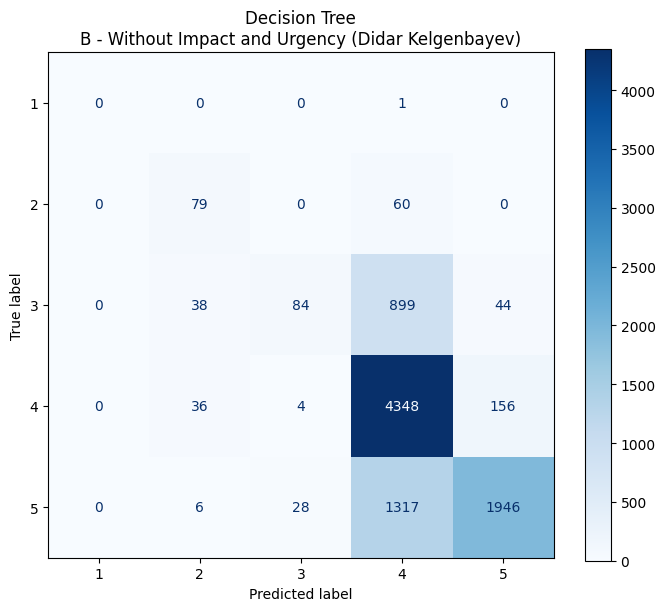

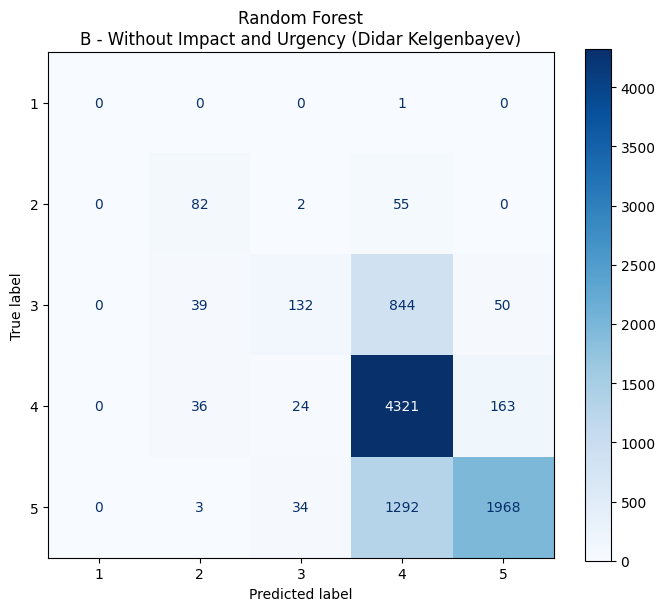

In [76]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for (experiment_name, model_name), model in research_models.items():
    selected_features = experiments[experiment_name]

    predictions = model.predict(
        test_df[selected_features]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[1, 2, 3, 4, 5],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(
        f"{model_name}\n{experiment_name} (Didar Kelgenbayev)"
    )

    plt.tight_layout()

    filename = (
        experiment_name.split(" - ")[0]
        + "_"
        + model_name.replace(" ", "_")
        + "_confusion_matrix.png"
    )

    plt.savefig(filename, dpi=300)
    plt.show()

16. Compare recall by priority

In [77]:
from sklearn.metrics import recall_score

recall_results = []

for (experiment_name, model_name), model in research_models.items():
    selected_features = experiments[experiment_name]

    predictions = model.predict(
        test_df[selected_features]
    )

    recalls = recall_score(
        y_test,
        predictions,
        labels=[1, 2, 3, 4, 5],
        average=None,
        zero_division=0
    )

    row = {
        "Experiment": experiment_name,
        "Model": model_name
    }

    for priority, value in zip([1, 2, 3, 4, 5], recalls):
        row[f"Priority {priority} Recall"] = value

    recall_results.append(row)

recall_df = pd.DataFrame(recall_results)

display(recall_df.round(4))

recall_df.to_csv(
    "research_priority_recall.csv",
    index=False
)

,Experiment,Model,Priority 1 Recall,Priority 2 Recall,Priority 3 Recall,Priority 4 Recall,Priority 5 Recall
0,A - With Impact and Urgency,Decision Tree,1.0,1.0000,0.9981,1.0000,1.0000
1,A - With Impact and Urgency,Random Forest,1.0,0.9928,0.9981,1.0000,1.0000
2,B - Without Impact and Urgency,Decision Tree,0.0,0.5683,0.0789,0.9569,0.5902
3,B - Without Impact and Urgency,Random Forest,0.0,0.5899,0.1239,0.9509,0.5969


17. Check priority assignment rules

In [78]:
# Check how Impact + Urgency relate to Priority

rule_table = pd.crosstab(
    [df_clean["Impact"], df_clean["Urgency"]],
    df_clean["Priority"]
)

# Calculate majority priority for each combination
majority_counts = rule_table.max(axis=1)

rule_consistency = (
    majority_counts.sum() / rule_table.values.sum()
)

print(
    f"Priority rule consistency: {rule_consistency:.4%}"
)

print("Priority counts for each Impact/Urgency combination:")
display(rule_table)

Priority rule consistency: 100.0000%
Priority counts for each Impact/Urgency combination:


Priority             1    2     3      4      5
Impact Urgency                                 
1      1             3    0     0      0      0
2      2             0  533     0      0      0
       3             0    2     0      0      0
       2             0  156     0      0      0
       3             0    1     0      0      0
3      2             0    3     0      0      0
       3             0    0  3420      0      0
       4             0    0   111      0      0
       5             0    0     0      4      0
       1             0    2     0      0      0
       3             0    0  1657      0      0
       4             0    0    33      0      0
       5             0    0     0      4      0
4      2             0    0     2      0      0
       3             0    0    76      0      0
       4             0    0     0  15223      0
       5             0    0     0    239      0
       2             0    0     1      0      0
       3             0    0    21      0      0
       4             0    0     0   6947      0
       5             0    0     0     47      0
5      1             0    0     1      0      0
       3             0    0     0      9      0
       4             0    0     0    172      0
       5             0    0     0      0  12041
       2             0    0     1      0      0
       3             0    0     0      2      0
       4             0    0     0     70      0
       5             0    0     0      0   4444
       5 - Very Low  0    0     0      0      1

18. Train-only priority lookup

In [79]:
from sklearn.metrics import accuracy_score, f1_score

# Learn priority mappings from training records only
rule_mapping = (
    train_df.groupby(["Impact", "Urgency"])["Priority"]
    .agg(lambda values: values.mode().iloc[0])
    .to_dict()
)

# Apply the learned mapping to test records
test_pairs = list(zip(
    test_df["Impact"],
    test_df["Urgency"]
))

rule_predictions = [
    rule_mapping.get(pair, None)
    for pair in test_pairs
]

# Check combinations unseen during training
unseen_count = sum(
    prediction is None
    for prediction in rule_predictions
)

print("Unseen combinations in test:", unseen_count)

# Evaluate only if every combination was seen in training
if unseen_count == 0:
    print(
        "Rule accuracy:",
        accuracy_score(y_test, rule_predictions)
    )
    print(
        "Rule macro F1:",
        f1_score(
            y_test,
            rule_predictions,
            average="macro",
            zero_division=0
        )
    )
else:
    print(
        "Some combinations were not present in training."
    )

Unseen combinations in test: 2
Some combinations were not present in training.


## 6. Investigate the two unseen combinations

19. Inspect unseen combinations and evaluate the rule

In [80]:
# Find incidents with unseen combinations
unseen_mask = [
    prediction is None
    for prediction in rule_predictions
]

unseen_records = test_df.loc[
    unseen_mask,
    ["Impact", "Urgency", "Priority"]
]

print("Unseen test incidents:")
display(unseen_records)

# Use the most common training priority as fallback
fallback_priority = y_train.mode().iloc[0]

final_rule_predictions = [
    prediction if prediction is not None
    else fallback_priority
    for prediction in rule_predictions
]

# Evaluate on ALL test records
rule_accuracy = accuracy_score(
    y_test,
    final_rule_predictions
)

rule_macro_f1 = f1_score(
    y_test,
    final_rule_predictions,
    average="macro",
    zero_division=0
)

print("Fallback priority:", fallback_priority)
print(f"Rule accuracy: {rule_accuracy:.4f}")
print(f"Rule macro F1: {rule_macro_f1:.4f}")

Unseen test incidents:


,Impact,Urgency,Priority
36251,5,2,3
30553,5,1,3


Fallback priority: 4
Rule accuracy: 0.9998
Rule macro F1: 0.9998


## Final research conclusion

The experiment investigated the influence of input features on machine-learning-based incident priority classification using the ITSM dataset. Decision Tree and Random Forest models were evaluated with and without the Impact and Urgency attributes. The Random Forest model achieved 99.97% accuracy and a macro F1-score of 0.9989 when both attributes were included. After removing them, accuracy decreased to 71.89% and macro F1-score decreased to 0.4517. Additional analysis showed that every observed combination of Impact and Urgency corresponded to a single priority class in the cleaned dataset. A simple priority lookup rule achieved 99.98% accuracy and a macro F1-score of 0.9998 on the test set, using a majority-class fallback for two unseen combinations. These findings indicate that the near-perfect classification performance is largely explained by the relationship between Impact, Urgency, and Priority, rather than evidence of advanced incident analysis capabilities.

## Export Figures (to generate and include)

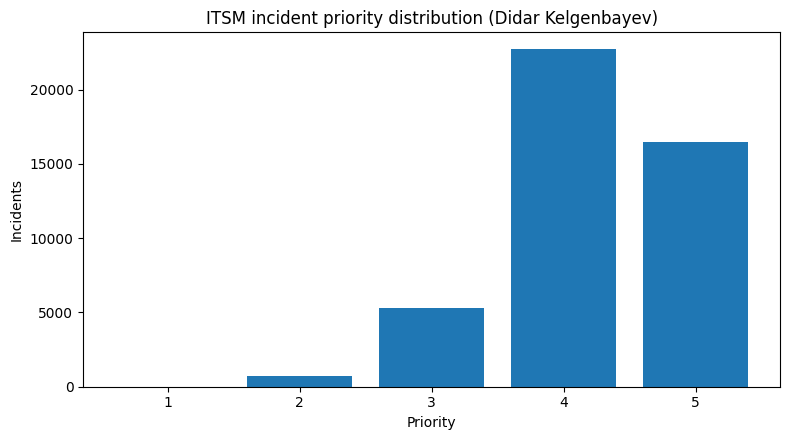

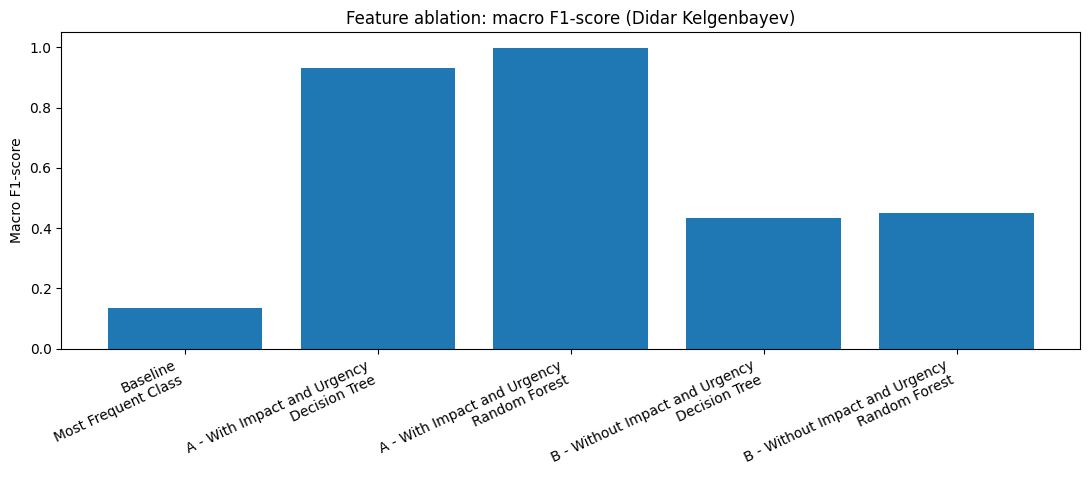

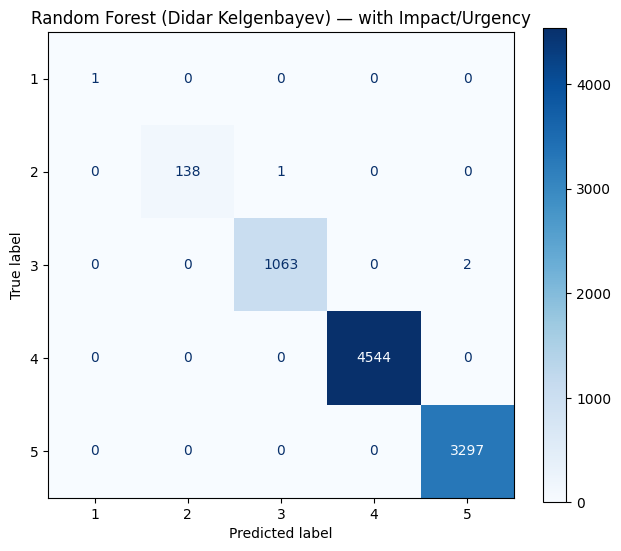

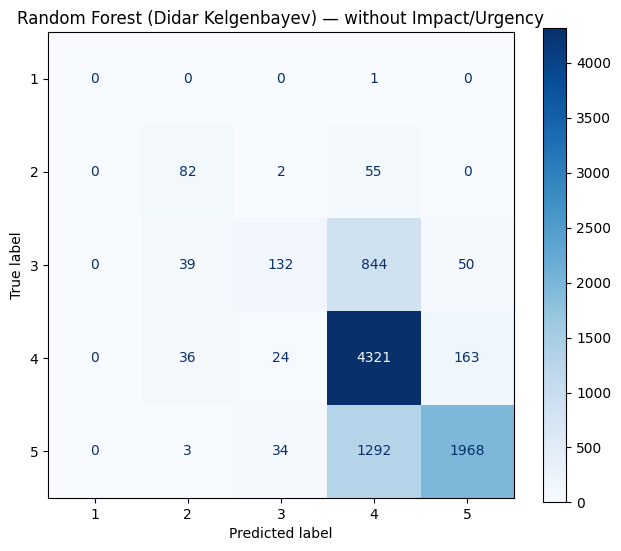

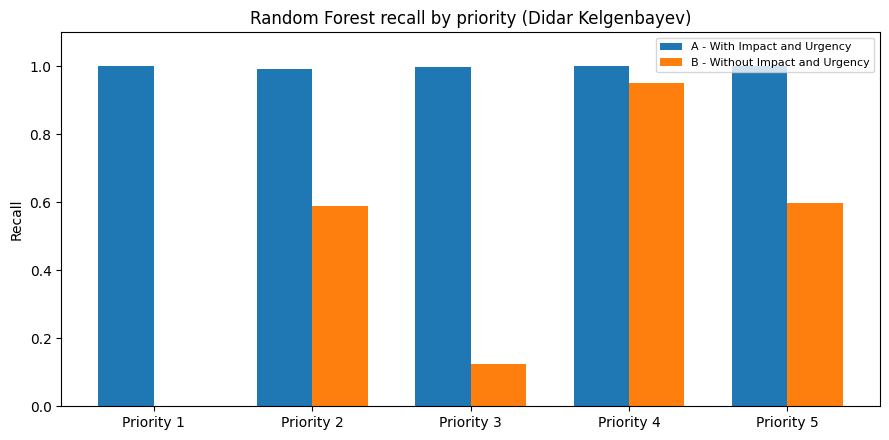

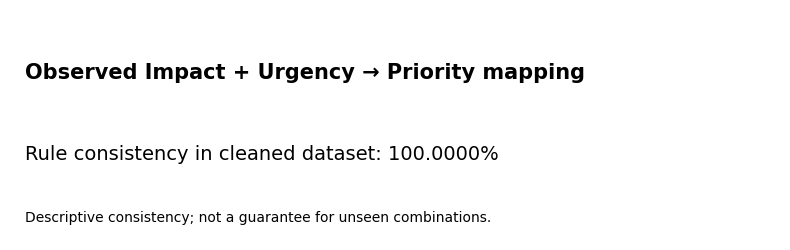

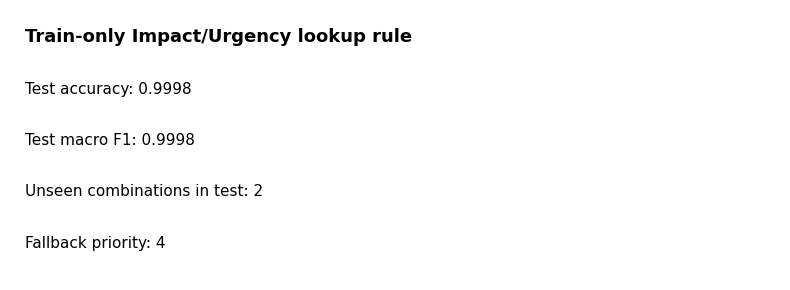

Saved: PW6_Experiment_1_Figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
# Run this as ONE NEW CELL at the end of your completed Experiment 1 notebook.
# It reuses variables already created by Cells 1–19. It does NOT retrain models.
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import display

folder = 'PW6_Experiment_1_Figures'
os.makedirs(folder, exist_ok=True)

# 1. Priority distribution
counts = df_clean['Priority'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(counts.index.astype(str), counts.values)
ax.set(title='ITSM incident priority distribution (Didar Kelgenbayev)', xlabel='Priority', ylabel='Incidents')
fig.tight_layout(); fig.savefig(f'{folder}/01_priority_distribution.png', dpi=300);plt.show()

# 2. Feature ablation (measured notebook results)
labels = final_results['Experiment'].astype(str) + '\n' + final_results['Model'].astype(str)
fig, ax = plt.subplots(figsize=(11,5))
ax.bar(labels, final_results['Macro F1'])
ax.set(title='Feature ablation: macro F1-score (Didar Kelgenbayev)', ylabel='Macro F1-score', ylim=(0,1.05))
ax.tick_params(axis='x', labelrotation=25)
for tick in ax.get_xticklabels(): tick.set_ha('right')
fig.tight_layout();fig.savefig(f'{folder}/02_feature_ablation.png', dpi=300);plt.show()

# 3–4. Real Random Forest confusion matrices from fitted models
for label, file in [('A - With Impact and Urgency','03_rf_with_impact_urgency.png'),('B - Without Impact and Urgency','04_rf_without_impact_urgency.png')]:
    # Select the actual experiment by its A/B prefix, independent of longer display name
    exp_name = next(k for k in experiments if k.startswith(label[0]))
    model = research_models[(exp_name, 'Random Forest')]
    preds = model.predict(test_df[experiments[exp_name]])
    fig, ax = plt.subplots(figsize=(6.5,5.5))
    ConfusionMatrixDisplay.from_predictions(y_test, preds, labels=[1,2,3,4,5], cmap='Blues', values_format='d', ax=ax)
    ax.set_title('Random Forest (Didar Kelgenbayev) — ' + ('with Impact/Urgency' if label.startswith('A') else 'without Impact/Urgency'))
    fig.tight_layout();fig.savefig(f'{folder}/{file}',dpi=300);plt.show()

# 5. Per-priority recall chart from notebook's actual recall_df
rf_recall = recall_df[recall_df['Model']=='Random Forest'].copy()
rf_recall = rf_recall.sort_values('Experiment')
columns = [f'Priority {i} Recall' for i in range(1,6)]
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(5);w=0.35
for j,(_,row) in enumerate(rf_recall.iterrows()):
    ax.bar(x+(j-.5)*w,[row[c] for c in columns],width=w,label=str(row['Experiment']))
ax.set(xticks=x,xticklabels=[f'Priority {i}' for i in range(1,6)],ylim=(0,1.1),ylabel='Recall',title='Random Forest recall by priority (Didar Kelgenbayev)')
ax.legend(fontsize=8);fig.tight_layout();fig.savefig(f'{folder}/05_rf_priority_recall.png',dpi=300);plt.show()

# 6. Export rule consistency as a reproducible figure (not a screenshot)
fig,ax=plt.subplots(figsize=(8,2.6));ax.axis('off')
ax.text(.02,.7,'Observed Impact + Urgency → Priority mapping',fontsize=15,weight='bold',transform=ax.transAxes)
ax.text(.02,.35,f'Rule consistency in cleaned dataset: {rule_consistency:.4%}',fontsize=14,transform=ax.transAxes)
ax.text(.02,.08,'Descriptive consistency; not a guarantee for unseen combinations.',fontsize=10,transform=ax.transAxes)
fig.tight_layout();fig.savefig(f'{folder}/06_rule_consistency.png',dpi=300);plt.show()

# 7. Export lookup results as a reproducible figure
fig,ax=plt.subplots(figsize=(8,3));ax.axis('off')
lines=['Train-only Impact/Urgency lookup rule',f'Test accuracy: {rule_accuracy:.4f}',f'Test macro F1: {rule_macro_f1:.4f}',f'Unseen combinations in test: {len(unseen_records)}',f'Fallback priority: {fallback_priority}']
for i,line in enumerate(lines):ax.text(.02,.88-i*.19,line,fontsize=13 if i==0 else 11,weight='bold' if i==0 else 'normal',transform=ax.transAxes)
fig.tight_layout();fig.savefig(f'{folder}/07_lookup_validation.png',dpi=300);plt.show()

# Zip the exported images for easy download from Colab
zip_name='PW6_Experiment_1_Figures.zip'
with zipfile.ZipFile(zip_name,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(os.listdir(folder)):
        z.write(os.path.join(folder,file),arcname=file)
print('Saved:',zip_name)
try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    print('Download the ZIP manually from the notebook files panel.')